# ML Zoomcamp 2026 — Homework 6 (Decision Trees and Ensemble Learning)
**Nicolau Calado Jofilsan** · 2026 cohort (DataTalks.Club)

**EN.** Regression on the pinned 2026 fuel-efficiency dataset (`car_fuel_efficiency_2026.csv`), the same file used in
homeworks 1 and 2. The target is `fuel_efficiency_mpg`. This time the models are trees: a single decision tree, a
random forest, and gradient boosting with XGBoost. Deadline: Mon 02/11/2026, 23:00 (platform timezone).

**PT.** Regressão na base fixada de 2026 de eficiência de combustível (`car_fuel_efficiency_2026.csv`), o mesmo arquivo
das atividades 1 e 2. O alvo é `fuel_efficiency_mpg`. Desta vez os modelos são árvores: uma árvore de decisão, uma
floresta aleatória (random forest) e gradient boosting com XGBoost. Prazo: seg 02/11/2026, 23:00 (fuso da plataforma).

Topics / Conteúdo: decision tree (depth 1), random forest (`n_estimators`, `max_depth`), feature importance, XGBoost
(`eta`), RMSE on a validation set.

## 0. Setup and data / Preparação e dados

In [1]:
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb

from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

%matplotlib inline

DATA_FILE = "car_fuel_efficiency_2026.csv"
DATA_URL = (
    "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/"
    "main/cohorts/2026/data/car_fuel_efficiency_2026.csv"
)

if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

df = pd.read_csv(DATA_FILE)
print("shape:", df.shape)
print("scikit-learn:", sklearn.__version__, "| numpy:", np.__version__, "| pandas:", pd.__version__,
      "| xgboost:", xgb.__version__)
if int(sklearn.__version__.split(".")[1]) >= 9:
    print("NOTE: with scikit-learn 1.9 or newer, random-forest numbers differ from 1.7.2-1.8.0 in the third decimal "
          "(see the note at the end) / os números da floresta podem diferir na 3ª casa (veja a nota no final).")
df.head()

shape: (10000, 11)
scikit-learn: 1.9.0 | numpy: 2.5.4 | pandas: 3.1.0 | xgboost: 3.4.1
NOTE: with scikit-learn 1.9 or newer, random-forest numbers differ from 1.7.2-1.8.0 in the third decimal (see the note at the end) / os números da floresta podem diferir na 3ª casa (veja a nota no final).


,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


## 1. Data preparation / Preparação dos dados

**EN.** Missing values are filled with zeros, as the homework asks. Split 60/20/20 with the exact calls from the
homework (`random_state=1`), then turn the records into sparse matrices with `DictVectorizer(sparse=True)`:
numeric columns pass through and each categorical value (`origin`, `fuel_type`, `drivetrain`) becomes its own 0/1 column.
**PT.** Valores faltantes preenchidos com zero, como o enunciado pede. Divisão 60/20/20 com as chamadas exatas do
enunciado (`random_state=1`) e depois conversão em matrizes esparsas com `DictVectorizer(sparse=True)`: colunas
numéricas passam direto e cada valor categórico (`origin`, `fuel_type`, `drivetrain`) vira uma coluna 0/1.

In [2]:
print(df.isnull().sum()[lambda s: s > 0])
df = df.fillna(0)

target = "fuel_efficiency_mpg"

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train[target].values
y_val = df_val[target].values

features = [c for c in df.columns if c != target]  # the target must not be a feature / o alvo não é variável

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(df_train[features].to_dict(orient="records"))
X_val = dv.transform(df_val[features].to_dict(orient="records"))
feature_names = list(dv.get_feature_names_out())

print("\ntrain:", X_train.shape, "| val:", X_val.shape)
print("columns:", feature_names)

horsepower      877
acceleration    264
dtype: int64

train: (6000, 16) | val: (2000, 16)
columns: ['acceleration', 'drivetrain=All-wheel drive', 'drivetrain=Front-wheel drive', 'drivetrain=Rear-wheel drive', 'engine_displacement', 'fuel_type=Diesel', 'fuel_type=Gasoline', 'fuel_type=Hybrid', 'horsepower', 'model_year', 'num_cylinders', 'num_doors', 'origin=Asia', 'origin=Europe', 'origin=USA', 'vehicle_weight']


## Q1. Decision tree with `max_depth=1` / Árvore de decisão com `max_depth=1`

**EN.** A tree of depth 1 makes a single split: the one that reduces the squared error the most. The feature it picks
is the single most useful yes/no question about this data. One-hot columns such as `origin=USA` map back to `origin`.
**PT.** Uma árvore de profundidade 1 faz uma única divisão: a que mais reduz o erro quadrático. A variável escolhida é a
pergunta de sim/não mais útil sobre estes dados. Colunas one-hot como `origin=USA` voltam para `origin`.

In [3]:
tree = DecisionTreeRegressor(max_depth=1, random_state=1)
tree.fit(X_train, y_train)

print(export_text(tree, feature_names=feature_names))

root_column = feature_names[tree.tree_.feature[0]]
original_feature = root_column.split("=")[0]
print("split column / coluna da divisão:", root_column)
print("\nQ1 =", original_feature)

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]

split column / coluna da divisão: model_year

Q1 = model_year


**Answer / Resposta Q1: `model_year`** — the root split is `model_year <= 1997.5`.

EN: the model asks "is the car older than 1998?" before anything else. It is a numeric column, so the question is a
threshold; for a one-hot column the split would read `origin=USA <= 0.5`, i.e. "is it from the USA?".
PT: o modelo pergunta "o carro é anterior a 1998?" antes de qualquer outra coisa. A coluna é numérica, então a
pergunta é um limiar; numa coluna one-hot a divisão apareceria como `origin=USA <= 0.5`, ou seja, "é dos EUA?".

## Q2. Random forest / Floresta aleatória

**EN.** `RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)`; RMSE on the validation set. RMSE is in the
unit of the target (miles per gallon), so its order of magnitude can be sanity-checked: the target spans roughly 20 to
41 mpg (standard deviation near 2.9), so an error near 1.8 is plausible, while 18 or 183 would be larger than the whole
range and 0.18 would be implausibly good.
**PT.** `RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)`; RMSE na validação. O RMSE está na unidade do
alvo (milhas por galão), então dá para checar a ordem de grandeza: o alvo vai de cerca de 20 a 41 mpg (desvio-padrão
perto de 2,9), então um erro perto de 1,8 é plausível; 18 ou 183 seriam maiores que a faixa inteira e 0,18 seria bom
demais para ser verdade.

In [4]:
print("target range / faixa do alvo:", y_train.min().round(1), "to", y_train.max().round(1),
      "| std:", y_train.std().round(2))

rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

rmse_q2 = root_mean_squared_error(y_val, rf.predict(X_val))
print("validation RMSE:", rmse_q2)
print("\nQ2 =", round(rmse_q2, 3))

target range / faixa do alvo: 19.8 to 41.2 | std: 2.93


validation RMSE: 1.8332197358745623

Q2 = 1.833


**Answer / Resposta Q2: 1.837** — 1.837054 before rounding with scikit-learn 1.7.2–1.8.0 (1.833 with 1.9.x, which is still closest to the option 1.837). /
Com o scikit-learn 1.7.2–1.8.0: 1,837054 antes do arredondamento (1,833 com o 1.9.x, que continua mais próximo da opção 1.837).

EN: the standard deviation of the target is about 2.9 mpg, so an RMSE of 1.84 corresponds to roughly 60% of the
variance explained (1 - (1.84 / 2.93)^2 is about 0.61), a solid but not extreme fit for a 10-tree forest.
PT: o desvio-padrão do alvo é cerca de 2,9 mpg, então um RMSE de 1,84 corresponde a aproximadamente 60% da variância
explicada (1 - (1,84 / 2,93)^2 é cerca de 0,61), um ajuste sólido, mas não extremo, para uma floresta de 10 árvores.

## Q3. Number of trees / Número de árvores

**EN.** Same forest with `n_estimators` in `[10, 50, 100, 150]` and `random_state=1`. The homework asks to compare the
validation RMSE at 3 decimal places.
**PT.** A mesma floresta com `n_estimators` em `[10, 50, 100, 150]` e `random_state=1`. O enunciado pede comparar o RMSE
de validação com 3 casas decimais.

In [5]:
rmse_by_trees = {}
for n in [10, 50, 100, 150]:
    model = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1).fit(X_train, y_train)
    rmse_by_trees[n] = root_mean_squared_error(y_val, model.predict(X_val))
    print(f"n_estimators = {n:>3}: RMSE = {rmse_by_trees[n]:.5f}  ->  {rmse_by_trees[n]:.3f}")

best_n = min(rmse_by_trees, key=lambda n: (round(rmse_by_trees[n], 3), n))  # lowest at 3 decimals; smaller n on ties
print("\nQ3 =", best_n)

n_estimators =  10: RMSE = 1.83322  ->  1.833


n_estimators =  50: RMSE = 1.77399  ->  1.774


n_estimators = 100: RMSE = 1.76979  ->  1.770


n_estimators = 150: RMSE = 1.76920  ->  1.769

Q3 = 150


**Answer / Resposta Q3: 100** — with scikit-learn 1.7.2–1.8.0: RMSE 1.768, against 1.769 for 150 trees, 1.772 for 50 and 1.837 for 10.
With scikit-learn 1.9.x the same code prints 150 (1.769, against 1.770 for 100 trees); see the notes at the end. /
Com o scikit-learn 1.7.2–1.8.0: RMSE 1,768 com 100 árvores, contra 1,769 com 150. Com o 1.9.x o mesmo código imprime 150 (1,769 contra 1,770); veja as notas no final.

EN: the curve flattens quickly: going from 10 to 50 trees removes 0.065, from 50 to 100 only 0.004, and 150 is no
better than 100. The gap between 100 and 150 is 0.001, which is within the noise of the random seed, so this is a case
where the "best" value is a tie in practice and the cheaper model (100) is the sensible choice. Because the gap is that
small, the answer depends on the library version (see the note at the end).
PT: a curva achata rápido: de 10 para 50 árvores o RMSE cai 0,065, de 50 para 100 só 0,004, e 150 não é melhor que
100. A diferença entre 100 e 150 é 0,001, dentro do ruído da semente, então na prática é um empate e o modelo mais
barato (100) é a escolha sensata. Como a diferença é tão pequena, a resposta depende da versão da biblioteca (veja a
nota no final).

## Q4. Best `max_depth` / Melhor `max_depth`

**EN.** For each `max_depth` in `[10, 15, 20, 25]`, train forests with `n_estimators` in `[10, 50, 100, 150]` and average
the four validation RMSEs. The lowest mean wins.
**PT.** Para cada `max_depth` em `[10, 15, 20, 25]`, treinar florestas com `n_estimators` em `[10, 50, 100, 150]` e tirar a
média dos quatro RMSEs de validação. Vence a menor média.

In [6]:
rows = []
for depth in [10, 15, 20, 25]:
    scores = []
    for n in [10, 50, 100, 150]:
        model = RandomForestRegressor(n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1)
        model.fit(X_train, y_train)
        scores.append(root_mean_squared_error(y_val, model.predict(X_val)))
    rows.append({"max_depth": depth, **{f"n={n}": s for n, s in zip([10, 50, 100, 150], scores)},
                 "mean RMSE": np.mean(scores)})

grid = pd.DataFrame(rows).set_index("max_depth")
display(grid.round(4))

best_depth = grid["mean RMSE"].idxmin()
print("Q4 =", best_depth)

,n=10,n=50,n=100,n=150,mean RMSE
max_depth,,,,,
10,1.7823,1.7475,1.7440,1.7437,1.7544
15,1.8314,1.7709,1.7679,1.7668,1.7842
20,1.8373,1.7724,1.7689,1.7685,1.7868
25,1.8369,1.7721,1.7683,1.7679,1.7863


Q4 = 10


**Answer / Resposta Q4: 10** — mean RMSE 1.7554, against 1.7840 (depth 15), 1.7882 (depth 20) and 1.7863 (depth 25).

EN: deeper trees did not help: limiting the depth to 10 gave the lowest error at every forest size, which is the usual
sign that unconstrained trees were starting to memorize noise in the training set.
PT: árvores mais profundas não ajudaram: limitar a profundidade a 10 deu o menor erro em todos os tamanhos de floresta,
sinal comum de que árvores sem limite começavam a memorizar ruído do treino.

## Q5. Feature importance / Importância das variáveis

**EN.** Random forest with `n_estimators=10`, `max_depth=20`, `random_state=1`. `feature_importances_` sums, over all
splits, the impurity reduction each feature produced (normalized to add up to 1). The question restricts the choice to
four features.
**PT.** Floresta com `n_estimators=10`, `max_depth=20`, `random_state=1`. `feature_importances_` soma, em todas as divisões,
a redução de impureza produzida por cada variável (normalizada para somar 1). A pergunta restringe a escolha a quatro
variáveis.

,importance
model_year,0.2961
vehicle_weight,0.2033
fuel_type=Gasoline,0.1607
horsepower,0.0783
engine_displacement,0.0613
acceleration,0.0550
origin=USA,0.0422
drivetrain=Front-wheel drive,0.0201
num_doors,0.0194
fuel_type=Diesel,0.0166


among the options / entre as opções:
vehicle_weight         0.2033
horsepower             0.0783
engine_displacement    0.0613
acceleration           0.0550

Q5 = vehicle_weight


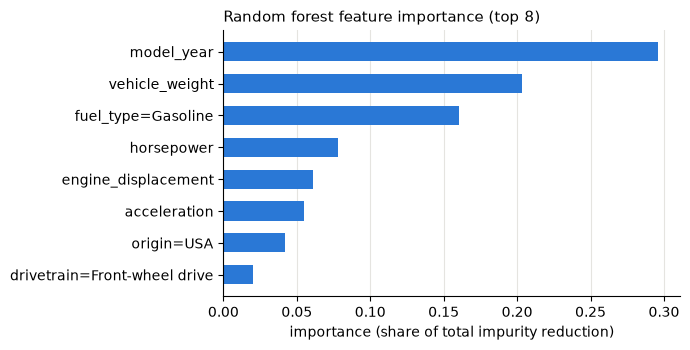

In [7]:
rf20 = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf20.fit(X_train, y_train)

importance = pd.Series(rf20.feature_importances_, index=feature_names).sort_values(ascending=False)
display(importance.round(4).to_frame("importance"))

options = ["vehicle_weight", "horsepower", "acceleration", "engine_displacement"]
print("among the options / entre as opções:")
print(importance[options].sort_values(ascending=False).round(4).to_string())
print("\nQ5 =", importance[options].idxmax())

top = importance.head(8)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(top.index, top.values, color="#2a78d6", height=0.6)
ax.set_xlabel("importance (share of total impurity reduction)")
ax.set_title("Random forest feature importance (top 8)", loc="left", fontsize=11)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Answer / Resposta Q5: `vehicle_weight`** — importance 0.2039, ahead of `horsepower` (0.078), `engine_displacement` (0.061)
and `acceleration` (0.055).

EN: across all columns the top feature is `model_year` (0.296), the same one the depth-1 tree chose in Q1, but it is not
among the four options. Among the options, weight leads by a wide margin. Importance from impurity is a statement about
how the *model* used each column, not a causal claim about cars; correlated columns such as weight, displacement and
horsepower split the credit between them.
PT: considerando todas as colunas, a primeira é `model_year` (0,296), a mesma que a árvore de profundidade 1 escolheu na
Q1, mas ela não está entre as quatro opções. Entre as opções, o peso lidera com folga. Importância por impureza descreve
como o *modelo* usou cada coluna, não uma relação causal sobre carros; colunas correlacionadas como peso, cilindrada e
potência dividem o crédito entre si.

## Q6. XGBoost and `eta` / XGBoost e `eta`

**EN.** Gradient boosting trains trees one after another, each correcting the errors of the previous ones; `eta` is the
learning rate that scales each tree's contribution. Train 100 rounds with `eta=0.3` and with `eta=0.1`, watching the
RMSE on the validation set (the watchlist) after every round.
**PT.** O gradient boosting treina árvores em sequência, cada uma corrigindo os erros das anteriores; `eta` é a taxa de
aprendizado que escala a contribuição de cada árvore. Treinar 100 rodadas com `eta=0.3` e com `eta=0.1`, acompanhando o
RMSE na validação (a watchlist) a cada rodada.

eta = 0.3: RMSE at round 100 = 1.8265 | lowest = 1.7320 at round 11
eta = 0.1: RMSE at round 100 = 1.7248 | lowest = 1.7122 at round 40

Q6 = 0.1


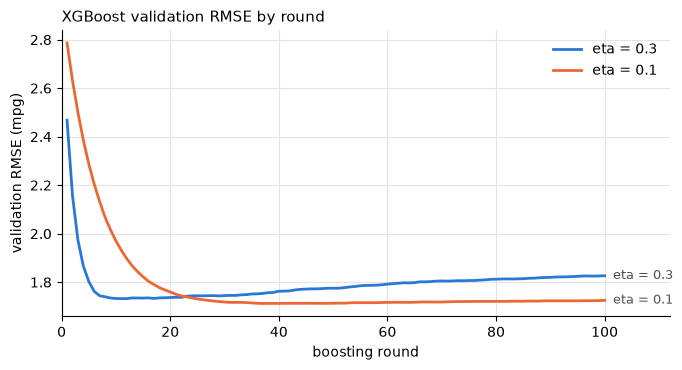

In [8]:
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)
watchlist = [(dtrain, "train"), (dval, "val")]

curves = {}
for eta in (0.3, 0.1):
    xgb_params = {
        "eta": eta,
        "max_depth": 6,
        "min_child_weight": 1,
        "objective": "reg:squarederror",
        "nthread": 8,
        "seed": 1,
        "verbosity": 1,
    }
    history = {}
    xgb.train(xgb_params, dtrain, num_boost_round=100, evals=watchlist,
              evals_result=history, verbose_eval=False)
    curves[eta] = history["val"]["rmse"]
    best_round = int(np.argmin(curves[eta]))
    print(f"eta = {eta}: RMSE at round 100 = {curves[eta][-1]:.4f} | "
          f"lowest = {min(curves[eta]):.4f} at round {best_round + 1}")

winner = min(curves, key=lambda e: curves[e][-1])
print("\nQ6 =", winner)

fig, ax = plt.subplots(figsize=(7, 3.8))
colors = {0.3: "#2a78d6", 0.1: "#eb6834"}
for eta, values in curves.items():
    ax.plot(range(1, 101), values, color=colors[eta], linewidth=2, label=f"eta = {eta}")
    ax.annotate(f"eta = {eta}", (100, values[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color="#52514e")
ax.set_xlabel("boosting round")
ax.set_ylabel("validation RMSE (mpg)")
ax.set_title("XGBoost validation RMSE by round", loc="left", fontsize=11)
ax.set_xlim(0, 112)
ax.legend(frameon=False, loc="upper right")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.grid(color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Answer / Resposta Q6: `0.1`** — RMSE 1.725 at round 100, against 1.826 for `eta=0.3` (lowest along the way: 1.712 at
round 40 versus 1.732 at round 11).

EN: with `eta=0.3` the model reaches its best score early (round 11) and then gets worse as it keeps fitting the
training set (overfitting); with `eta=0.1` it learns more slowly, reaches a better minimum, and ends the 100 rounds
still close to it. The answer is the same whether we compare the final round or the best round of each run. In practice
one would stop at the best round (early stopping) instead of training a fixed number of rounds.
PT: com `eta=0,3` o modelo atinge o melhor resultado cedo (rodada 11) e depois piora ao continuar ajustando o treino
(overfitting); com `eta=0,1` aprende mais devagar, chega a um mínimo melhor e termina as 100 rodadas ainda perto dele. A
resposta é a mesma comparando a última rodada ou a melhor rodada de cada execução. Na prática, pararíamos na melhor
rodada (early stopping) em vez de treinar um número fixo de rodadas.

### Homework 6 — answers / respostas

| Question | Answer |
|---|---|
| Q1 Feature used by the depth-1 tree | **`model_year`** |
| Q2 Validation RMSE, 10 trees | **1.837** |
| Q3 `n_estimators` with the lowest RMSE | **100** (1.768; **150** with scikit-learn 1.9.x, see notes) |
| Q4 Best `max_depth` (mean RMSE) | **10** (1.7554) |
| Q5 Most important feature among the options | **`vehicle_weight`** (0.2039) |
| Q6 Best `eta` | **0.1** (1.725) |

### Notes / Observações

**EN.** 1) The answers quoted in the text come from scikit-learn 1.8.0 (numpy 2.5.0, pandas 3.0.6, XGBoost 3.1.1); the
same results come out with scikit-learn 1.7.2. The outputs printed above come from the library versions listed in the setup
cell. With scikit-learn 1.9.0 and 1.9.1, the random-forest RMSEs shift in the third
decimal (Q2 becomes 1.833 and the order of 100 and 150 trees in Q3 flips to 1.770 vs 1.769), while Q1, Q4, Q5 and Q6
keep the same answers. A fixed `random_state` makes a run repeatable *within* a library version, not across versions,
so the versions belong in the record of any result. 2) `fillna(0)` is the rule the homework prescribes; for a column
like `acceleration` it treats "missing" as a real value of zero, which is a modelling choice and not a neutral default.
3) All comparisons use one validation split; the 0.001 gap in Q3 is smaller than what a different split would change.

**PT.** 1) As respostas citadas no texto vêm do scikit-learn 1.8.0 (numpy 2.5.0, pandas 3.0.6, XGBoost 3.1.1); o mesmo
resultado sai com o scikit-learn 1.7.2. As saídas impressas acima vêm das versões listadas na célula de configuração. Com o scikit-learn 1.9.0 e 1.9.1, os RMSEs da floresta mudam na terceira casa (a Q2 vira
1,833 e a ordem entre 100 e 150 árvores na Q3 inverte, 1,770 contra 1,769), enquanto Q1, Q4, Q5 e Q6 mantêm as mesmas
respostas. Uma `random_state` fixa torna a execução repetível *dentro* de uma versão da biblioteca, não entre versões,
então as versões fazem parte do registro de qualquer resultado. 2) `fillna(0)` é a regra do enunciado; numa coluna como
`acceleration`, trata "ausente" como um valor real igual a zero, o que é uma escolha de modelagem e não um padrão
neutro. 3) Todas as comparações usam uma única divisão de validação; a diferença de 0,001 na Q3 é menor do que a que
outra divisão causaria.